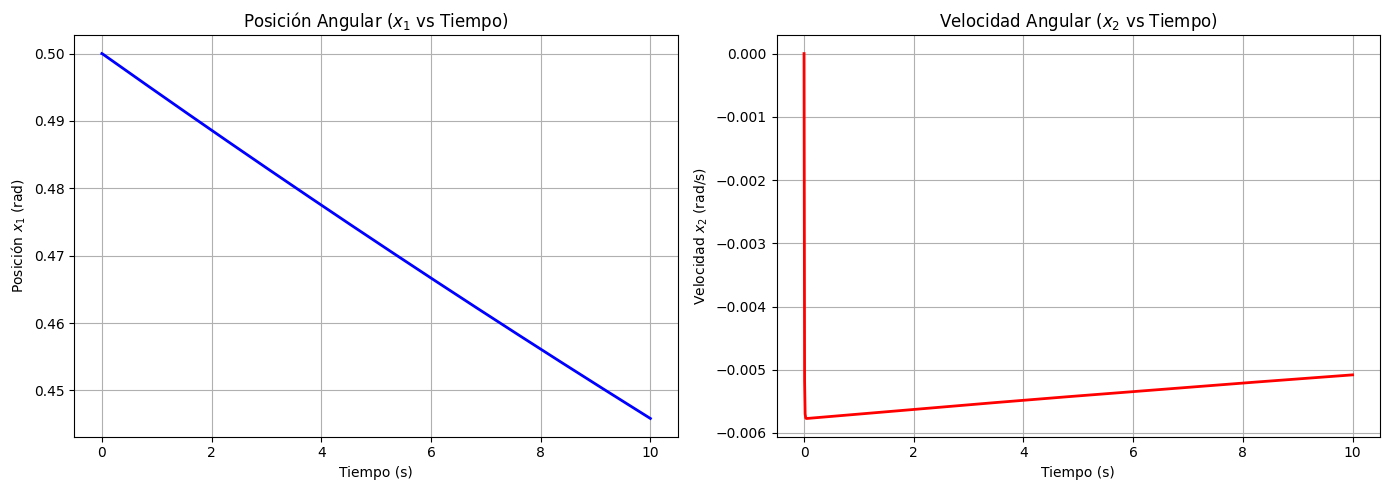

In [3]:
# ==============================================================================
# AF 5.- Simulación de un sistema a partir de ecuaciones de Euler-Lagrange
# Sistema: Péndulo-Robot
#
# Integrantes del equipo:
# - Roberto Ortega Sandoval - 2107169
# - Saúl Isaí Lizcano Montoya - 2010705
# - Ricardo Martínez Plata - 2021191
# - Christian Aguilar Gómez - 2096577
# - Kevin Rivera Magallanes - 2177938
# ==============================================================================

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 1. Parámetros del sistema (según la instrucción)
I = 0.16       # Momento de inercia
m = 5.0        # Masa total del mecanismo
g = 9.81       # Aceleración de la gravedad
lc = 0.01      # Distancia al centro de masa
b = 0.14       # Coeficiente de fricción viscosa
fc = 0.45      # Fricción de Coulomb

# 2. Definición del sistema en espacio de estados
def sistema_pendulo(t, X):
    x1, x2 = X

    tau = 0.0  # Torque del motor

    # Fricción total: Usamos np.tanh en lugar de np.sign para suavizar
    # la fricción de Coulomb y evitar el ruido numérico en las gráficas.
    f = b * x2 + fc * np.tanh(100 * x2)

    # Denominador de la ecuación de aceleración
    den = m * (lc**2) + I

    # Ecuaciones de estado
    dx1_dt = x2
    dx2_dt = (1.0 / den) * (tau - m * g * lc * np.sin(x1) - f)

    return [dx1_dt, dx2_dt]

# 3. Condiciones iniciales y tiempo de simulación
X0 = [0.5, 0.0]                   # Posición inicial de 0.5 rad (~28°) y velocidad 0
t_span = (0, 10)                  # Tiempo total de 10 segundos
t_eval = np.linspace(0, 10, 1000) # Puntos de evaluación para una curva suave

# 4. Resolución numérica usando Runge-Kutta con alta precisión
sol = solve_ivp(sistema_pendulo, t_span, X0, t_eval=t_eval, rtol=1e-6, atol=1e-8)

# 5. Visualización de los resultados
plt.figure(figsize=(14, 5))

# Gráfica de Posición Angular
plt.subplot(1, 2, 1)
plt.plot(sol.t, sol.y[0], 'b-', linewidth=2)
plt.title('Posición Angular ($x_1$ vs Tiempo)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición $x_1$ (rad)')
plt.grid(True)

# Gráfica de Velocidad Angular
plt.subplot(1, 2, 2)
plt.plot(sol.t, sol.y[1], 'r-', linewidth=2)
plt.title('Velocidad Angular ($x_2$ vs Tiempo)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad $x_2$ (rad/s)')
plt.grid(True)

plt.tight_layout()
plt.show()